# 02. 데이터셋·증강 확인
담당: 데이터 B · `src/dataset.py`, `src/transforms.py`가 팀 표준 형식(xyxy, label_idx, RGB 0~1)을 지키는지 눈으로 확인합니다.

In [11]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from src.utils import load_class_map, load_config
from src.visualize import set_korean_font

set_korean_font()
pd.set_option("display.max_columns", 50)

CONFIG = "configs/base.yaml"  # 샘플 데이터로 연습: "configs/sample_yolo.yaml"
cfg = load_config(CONFIG)
d = cfg["data"]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
from src.dataset import PillDataset, load_records, load_split
from src.transforms import get_transforms

records, _ = load_records(d["train_annotations"])
class_map = load_class_map(d["class_map"])
train_records = load_split(records, f"{d['split_dir']}/{d['version']}/train.txt")
ds = PillDataset(
    train_records,
    d["train_images"],
    class_map,
    transforms=get_transforms(
        {"name": "basic", "hflip": 0.5, "vflip": 0.5, "brightness": 0.2 , "rotate90":0.5}, train=True
    ),
)
img, target = ds[0]
print(img.shape, img.dtype, float(img.min()), float(img.max()))
target

torch.Size([3, 976, 1280]) torch.float32 0.10588235408067703 0.9058823585510254


{'boxes': tensor([[ 245.,  143.,  435.,  332.],
         [ 242.,  593.,  481.,  832.],
         [ 843.,  164.,  993.,  319.],
         [ 798.,  476., 1062.,  868.]]),
 'labels': tensor([ 0, 15, 22, 42]),
 'image_id': 34,
 'orig_size': (1280, 976)}

## 형식 검사
아래 셀이 오류 없이 지나가야 합니다. (`tests/test_dataset.py`와 같은 검사)

In [13]:
for i in range(min(20, len(ds))):
    img, t = ds[i]
    assert img.shape[0] == 3 and img.max() <= 1.0
    b = t["boxes"]
    assert (b[:, 2] > b[:, 0]).all() and (b[:, 3] > b[:, 1]).all(), "xyxy 형식이 아님"
    assert t["labels"].min() >= 0 and t["labels"].max() < len(class_map)
print("형식 검사 통과")

형식 검사 통과


## 증강 결과 보기
같은 이미지를 여러 번 꺼내 박스가 이미지와 함께 움직이는지 확인합니다.

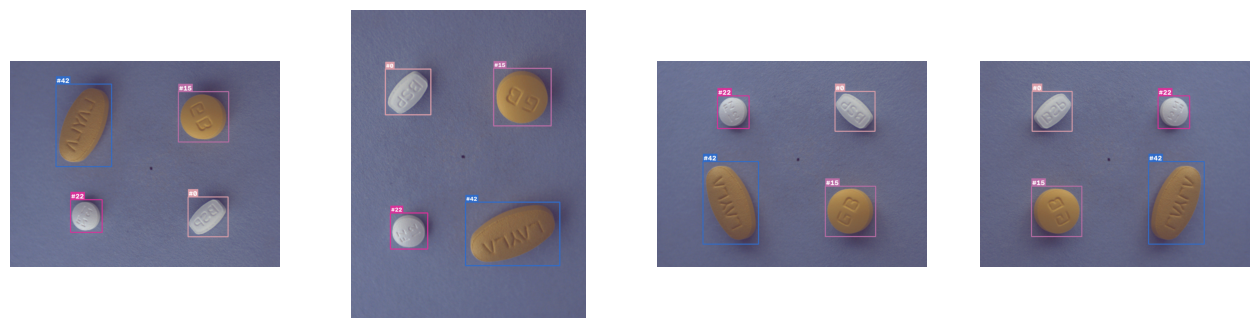

In [14]:
import matplotlib.pyplot as plt

from src.visualize import draw_boxes

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax in axes:
    img, t = ds[0]
    ax.imshow(
        draw_boxes((img.permute(1, 2, 0).numpy() * 255).astype("uint8"), t["boxes"], t["labels"])
    )
    ax.axis("off")
plt.show()

## 분할 확인

In [15]:
val_records = load_split(records, f"{d['split_dir']}/{d['version']}/val.txt")
train_cls = {c for r in train_records for c in r["category_ids"]}
val_cls = {c for r in val_records for c in r["category_ids"]}
print(f"train {len(train_records)}장 / val {len(val_records)}장")
print(f"검증셋에만 있는 클래스: {sorted(val_cls - train_cls)}")

train 185장 / val 47장
검증셋에만 있는 클래스: []
